# A tiny physics-informed neural network for structural health monitoring

**System:** damped single-degree-of-freedom oscillator, `m x'' + c x' + k x = 0`

**Questions**
1. *Forward problem:* can a neural network learn the free-vibration response using only the equation of motion and the initial conditions?
2. *Inverse problem:* if the stiffness `k` is unknown, can the network find it from a few noisy measurements?
3. *Damage detection and data scarcity:* does the recovered `k` drop when the structure is damaged, and does the physics help when data is scarce?

Run the cells from top to bottom. The whole notebook takes roughly 5-10 minutes on a laptop CPU.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 0
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 1. Problem setup
Everything is chosen so that values are of order 1 (this makes training much more stable).
The exact solution is known, so we can check the network against it.

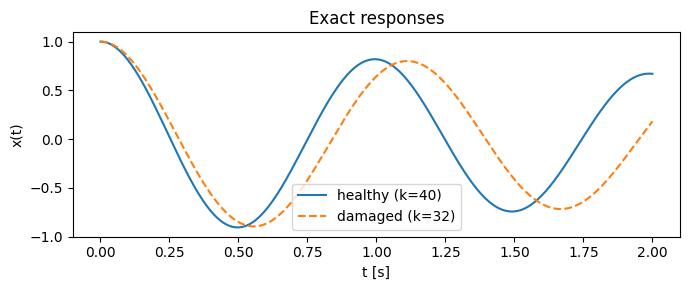

In [4]:
m, c = 1.0, 0.4          # mass and damping (known)
K_TRUE = 40.0            # healthy stiffness  -> natural frequency about 1 Hz
K_DAMAGED = 32.0         # 20 % stiffness loss (simulated damage)
X0, V0 = 1.0, 0.0        # initial displacement and velocity (known)
T = 2.0                  # time window [s], about two cycles
K_REF = 40.0             # only used to scale the residual so the loss terms are comparable

def analytical(t, k):
    """Exact free-vibration response of the underdamped oscillator."""
    wn = np.sqrt(k / m)
    zeta = c / (2.0 * np.sqrt(k * m))
    wd = wn * np.sqrt(1.0 - zeta**2)
    return np.exp(-zeta * wn * t) * (X0 * np.cos(wd * t) + (V0 + zeta * wn * X0) / wd * np.sin(wd * t))

t_dense = np.linspace(0.0, T, 400)

plt.figure(figsize=(7, 3))
plt.plot(t_dense, analytical(t_dense, K_TRUE), label=f"healthy (k={K_TRUE:.0f})")
plt.plot(t_dense, analytical(t_dense, K_DAMAGED), "--", label=f"damaged (k={K_DAMAGED:.0f})")
plt.xlabel("t [s]"); plt.ylabel("x(t)"); plt.legend(); plt.title("Exact responses")
plt.tight_layout(); plt.show()

## 2. Building blocks
* `make_model()` : a small fully connected network `t -> x(t)` with tanh activations.
* `residual()` : the equation of motion evaluated on the network. Derivatives come from automatic differentiation. If the network is physically correct, this is zero everywhere.
* `ic_loss()` : penalises violation of the initial conditions.
* `train()` : a generic Adam training loop that can also train extra variables (like the unknown stiffness).

In [5]:
def make_model(width=64, depth=4):
    layers = [tf.keras.layers.Input(shape=(1,)),
              tf.keras.layers.Rescaling(1.0 / T)]          # scale time to [0, 1] inside the model
    for _ in range(depth):
        layers.append(tf.keras.layers.Dense(width, activation="tanh"))
    layers.append(tf.keras.layers.Dense(1))
    return tf.keras.Sequential(layers)


def residual(model, t, k):
    """(m x'' + c x' + k x) / K_REF, with x'' and x' from automatic differentiation."""
    with tf.GradientTape() as g2:
        g2.watch(t)
        with tf.GradientTape() as g1:
            g1.watch(t)
            x = model(t)
        dx = g1.gradient(x, t)
    d2x = g2.gradient(dx, t)
    return (m * d2x + c * dx + k * x) / K_REF


def ic_loss(model):
    """Squared error on x(0) = X0 and x'(0) = V0."""
    t0 = tf.zeros((1, 1))
    with tf.GradientTape() as g:
        g.watch(t0)
        x_0 = model(t0)
    v_0 = g.gradient(x_0, t0)
    return tf.square(x_0[0, 0] - X0) + tf.square(v_0[0, 0] - V0)


def train(model, loss_fn, steps, extra_vars=(), lr=2e-3, track=None, track_every=50, verbose_every=1000):
    """Generic Adam loop. `track` is an optional function returning a float to record (e.g. the current k)."""
    variables = list(model.trainable_variables) + list(extra_vars)
    schedule = tf.keras.optimizers.schedules.ExponentialDecay(lr, decay_steps=1000, decay_rate=0.85)
    opt = tf.keras.optimizers.Adam(schedule)

    @tf.function
    def step():
        with tf.GradientTape() as tape:
            loss = loss_fn()
        grads = tape.gradient(loss, variables)
        opt.apply_gradients(zip(grads, variables))
        return loss

    history = []
    for i in range(steps):
        loss = step()
        if track is not None and i % track_every == 0:
            history.append(track())
        if verbose_every and i % verbose_every == 0:
            print(f"step {i:5d}   loss = {float(loss):.3e}")
    return history


def predict(model, t):
    return model(tf.constant(t.reshape(-1, 1), dtype=tf.float32)).numpy().ravel()

## 3. Step 1 - Forward problem (no measurements at all)
The only ingredient is the equation of motion, evaluated at 200 collocation points.

A plain PINN with a soft penalty on the initial conditions trains poorly on oscillatory problems (a well-known weakness), so here the initial conditions are built into the network:
`x(t) = X0 + V0 t + (t/T)^2 * N(t)`. This satisfies `x(0) = X0` and `x'(0) = V0` exactly for any network `N`, and the network only has to satisfy the equation of motion.
If it reproduces the exact solution, the physics-informed machinery works.

step     0   loss = 1.011e+00
step  3000   loss = 4.208e-03
step  6000   loss = 1.173e-03
step  9000   loss = 4.628e-04
step 12000   loss = 2.216e-04

Forward PINN RMSE vs exact solution: 0.0111


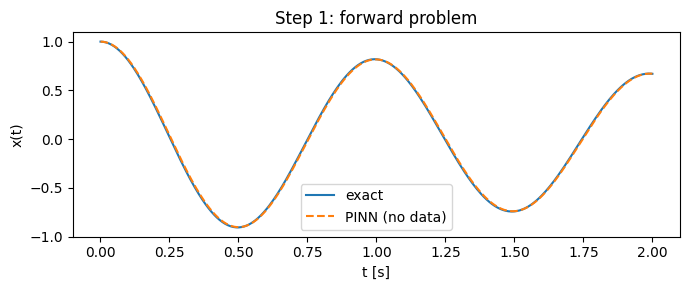

In [6]:
t_col = tf.constant(np.linspace(0.0, T, 200).reshape(-1, 1), dtype=tf.float32)


class HardICModel(tf.keras.Model):
    """x(t) = X0 + V0 t + (t/T)^2 * N(t): initial conditions hold exactly."""
    def __init__(self):
        super().__init__()
        self.net = make_model()

    def call(self, t):
        return X0 + V0 * t + tf.square(t / T) * self.net(t)


tf.random.set_seed(SEED)
fwd_model = HardICModel()

def forward_loss():
    return tf.reduce_mean(tf.square(residual(fwd_model, t_col, K_TRUE)))

train(fwd_model, forward_loss, steps=15000, lr=3e-3, verbose_every=3000)

x_pred = predict(fwd_model, t_dense)
x_true = analytical(t_dense, K_TRUE)
print(f"\nForward PINN RMSE vs exact solution: {np.sqrt(np.mean((x_pred - x_true)**2)):.4f}")

plt.figure(figsize=(7, 3))
plt.plot(t_dense, x_true, label="exact")
plt.plot(t_dense, x_pred, "--", label="PINN (no data)")
plt.xlabel("t [s]"); plt.ylabel("x(t)"); plt.legend(); plt.title("Step 1: forward problem")
plt.tight_layout(); plt.show()

## 4. Step 2 - Inverse problem: find the stiffness from noisy measurements
Now `k` is **unknown**. We make it a trainable variable (stored as `log k` so it stays positive), start from a wrong guess, and train the network on:
* the data misfit at the measurement times,
* the equation-of-motion residual (using the current `k`),
* the initial conditions.

Change `N_POINTS` and `NOISE_STD` at the top of the next cell to see how much data you need.

In [7]:
N_POINTS = 20       # number of noisy measurements
NOISE_STD = 0.02    # measurement noise (amplitude of the response is 1)
K_INIT = 20.0       # deliberately wrong starting guess
STEPS_INV = 8000


def make_data(k, n_points, noise_std, seed):
    rng = np.random.default_rng(seed)
    t_meas = np.sort(rng.uniform(0.0, T, n_points))
    x_meas = analytical(t_meas, k) + rng.normal(0.0, noise_std, n_points)
    return t_meas, x_meas


def run_inverse(k_true, seed=1, label=""):
    t_meas, x_meas = make_data(k_true, N_POINTS, NOISE_STD, seed)
    t_m = tf.constant(t_meas.reshape(-1, 1), dtype=tf.float32)
    x_m = tf.constant(x_meas.reshape(-1, 1), dtype=tf.float32)

    model = make_model()
    log_k = tf.Variable(np.log(K_INIT), dtype=tf.float32)

    def loss():
        k = tf.exp(log_k)
        data_term = tf.reduce_mean(tf.square(model(t_m) - x_m))
        phys_term = tf.reduce_mean(tf.square(residual(model, t_col, k)))
        return data_term + phys_term + ic_loss(model)

    print(f"--- inverse problem {label} (true k = {k_true}) ---")
    k_hist = train(model, loss, STEPS_INV, extra_vars=[log_k],
                   lr=3e-3, track=lambda: float(tf.exp(log_k)))
    k_est = float(tf.exp(log_k))
    print(f"recovered k = {k_est:.2f}   (true {k_true:.2f}, error {100*(k_est-k_true)/k_true:+.1f} %)\n")
    return model, k_est, k_hist, (t_meas, x_meas)


healthy = run_inverse(K_TRUE, seed=1, label="healthy")

--- inverse problem healthy (true k = 40.0) ---
step     0   loss = 1.426e+00
step  1000   loss = 4.443e-03
step  2000   loss = 6.647e-03
step  3000   loss = 5.676e-04
step  4000   loss = 7.419e-04
step  5000   loss = 5.548e-04
step  6000   loss = 9.604e-04
step  7000   loss = 4.849e-04
recovered k = 39.78   (true 40.00, error -0.5 %)



## 5. Step 3a - Damage detection
Same procedure, but the measurements come from the damaged structure (k = 32). The *estimated* stiffness should drop by about 20 % compared with the healthy case.

--- inverse problem damaged (true k = 32.0) ---
step     0   loss = 1.327e+00
step  1000   loss = 7.206e-04
step  2000   loss = 4.395e-04
step  3000   loss = 4.794e-04
step  4000   loss = 3.565e-04
step  5000   loss = 5.109e-04
step  6000   loss = 5.501e-04
step  7000   loss = 4.047e-04
recovered k = 31.89   (true 32.00, error -0.4 %)

Estimated stiffness change: -19.8 %   (true change: -20.0 %)


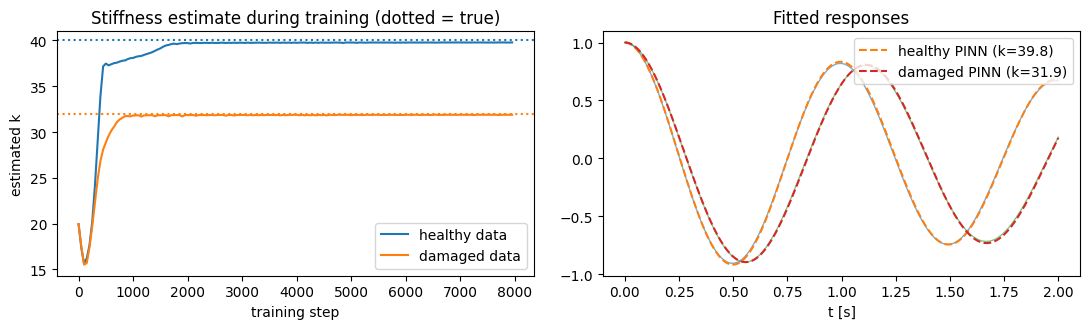

In [8]:
damaged = run_inverse(K_DAMAGED, seed=2, label="damaged")

k_h, k_d = healthy[1], damaged[1]
print(f"Estimated stiffness change: {100 * (k_d - k_h) / k_h:+.1f} %   (true change: {100 * (K_DAMAGED - K_TRUE) / K_TRUE:+.1f} %)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
steps_axis = np.arange(len(healthy[2])) * 50
ax[0].plot(steps_axis, healthy[2], label="healthy data")
ax[0].plot(steps_axis, damaged[2], label="damaged data")
ax[0].axhline(K_TRUE, color="C0", ls=":"); ax[0].axhline(K_DAMAGED, color="C1", ls=":")
ax[0].set_xlabel("training step"); ax[0].set_ylabel("estimated k"); ax[0].legend()
ax[0].set_title("Stiffness estimate during training (dotted = true)")

for (model, k_est, _, (tm, xm)), k_true, name in [(healthy, K_TRUE, "healthy"), (damaged, K_DAMAGED, "damaged")]:
    ax[1].plot(t_dense, analytical(t_dense, k_true), lw=1, alpha=0.6)
    ax[1].plot(t_dense, predict(model, t_dense), "--", label=f"{name} PINN (k={k_est:.1f})")
ax[1].set_xlabel("t [s]"); ax[1].legend(); ax[1].set_title("Fitted responses")
plt.tight_layout(); plt.show()

## 6. Step 3b - Does the physics help when data is scarce?
We train an ordinary network on the **same** noisy measurements (no equation of motion, no initial conditions) and compare how well each model predicts the full response.

*This is a single run with an untuned baseline, so treat it as an illustration. Section 8 repeats the comparison over several seeds and data sizes with a stronger baseline.*

RMSE vs exact response with 20 noisy points:
  physics-informed : 0.0094
  data-only        : 0.0519


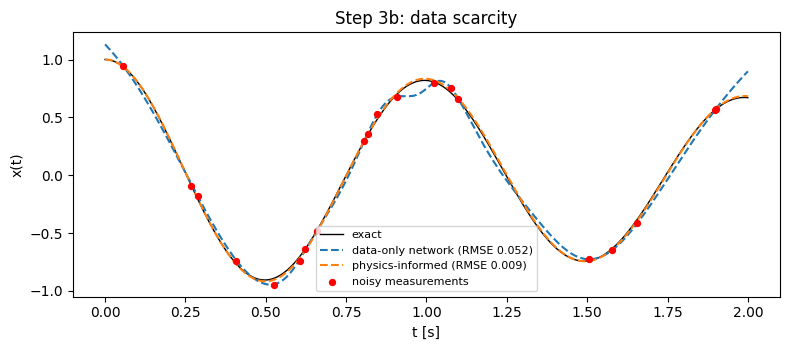

In [9]:
def run_data_only(t_meas, x_meas, steps=STEPS_INV):
    t_m = tf.constant(t_meas.reshape(-1, 1), dtype=tf.float32)
    x_m = tf.constant(x_meas.reshape(-1, 1), dtype=tf.float32)
    model = make_model()
    train(model, lambda: tf.reduce_mean(tf.square(model(t_m) - x_m)), steps, lr=3e-3, verbose_every=0)
    return model

pinn_model, _, _, (tm, xm) = healthy
plain_model = run_data_only(tm, xm)

x_true = analytical(t_dense, K_TRUE)
rmse = lambda a: np.sqrt(np.mean((a - x_true) ** 2))
rmse_pinn = rmse(predict(pinn_model, t_dense))
rmse_plain = rmse(predict(plain_model, t_dense))
print(f"RMSE vs exact response with {N_POINTS} noisy points:")
print(f"  physics-informed : {rmse_pinn:.4f}")
print(f"  data-only        : {rmse_plain:.4f}")

plt.figure(figsize=(8, 3.6))
plt.plot(t_dense, x_true, "k", lw=1, label="exact")
plt.plot(t_dense, predict(plain_model, t_dense), "--", label=f"data-only network (RMSE {rmse_plain:.3f})")
plt.plot(t_dense, predict(pinn_model, t_dense), "--", label=f"physics-informed (RMSE {rmse_pinn:.3f})")
plt.scatter(tm, xm, c="r", s=18, zorder=5, label="noisy measurements")
plt.xlabel("t [s]"); plt.ylabel("x(t)"); plt.legend(fontsize=8); plt.title("Step 3b: data scarcity")
plt.tight_layout(); plt.show()

## 8. Step 4 - Repeating the experiment properly
The single runs above can be lucky. Here we repeat everything for several random seeds and for different numbers of measurements, and we use a **stronger baseline**.

* **PINN:** same inverse problem as before (unknown `k`), run on *healthy* and *damaged* data. Healthy and damaged runs share the same seed, so they use the same measurement times and noise (a paired comparison).
* **Data-only baseline (two numbers per run):**
  a smaller network (3 x 32) trained only on the measurements, and evaluated at several checkpoints during training.
  *final* = the untuned result after the last step (what you get without early stopping).
  *best checkpoint* = the lowest error over all checkpoints, picked using the exact solution. This is **optimistic for the baseline** (a real user could not do this), so if the PINN still wins against it, the claim is conservative.

Settings are at the top of the next cell. The default (4 data sizes x 5 seeds x 2 PINN runs) takes roughly 10-20 minutes on a laptop CPU; reduce `SEEDS` or `N_LIST` for a quick test.

In [10]:
import time, gc

N_LIST = [5, 10, 20, 40]          # numbers of noisy measurements to test
SEEDS = [0, 1, 2, 3, 4]           # random seeds (measurement times, noise, network initialisation)
NOISE_SWEEP = 0.02
STEPS_SWEEP = 5000
BASE_CHECKS = (300, 600, 1000, 2000, 3000, 4500, 6000)

x_true_h = analytical(t_dense, K_TRUE)


def pinn_estimate(k_true, n_points, noise_std, seed, steps=STEPS_SWEEP):
    tf.keras.backend.clear_session()   # free memory from earlier runs
    t_meas, x_meas = make_data(k_true, n_points, noise_std, seed)
    t_m = tf.constant(t_meas.reshape(-1, 1), dtype=tf.float32)
    x_m = tf.constant(x_meas.reshape(-1, 1), dtype=tf.float32)
    tf.random.set_seed(seed)
    model = make_model()
    log_k = tf.Variable(np.log(K_INIT), dtype=tf.float32)

    def loss():
        k = tf.exp(log_k)
        return (tf.reduce_mean(tf.square(model(t_m) - x_m))
                + tf.reduce_mean(tf.square(residual(model, t_col, k)))
                + ic_loss(model))

    train(model, loss, steps, extra_vars=[log_k], lr=3e-3, verbose_every=0)
    return model, float(tf.exp(log_k))


def baseline_rmse(t_meas, x_meas, seed, width=32, depth=3, checks=BASE_CHECKS):
    """Data-only network. Returns (RMSE after the last step, lowest RMSE over the checkpoints)."""
    tf.keras.backend.clear_session()
    t_m = tf.constant(t_meas.reshape(-1, 1), dtype=tf.float32)
    x_m = tf.constant(x_meas.reshape(-1, 1), dtype=tf.float32)
    tf.random.set_seed(seed)
    model = make_model(width, depth)
    opt = tf.keras.optimizers.Adam(3e-3)
    variables = model.trainable_variables

    @tf.function
    def step():
        with tf.GradientTape() as tape:
            loss = tf.reduce_mean(tf.square(model(t_m) - x_m))
        opt.apply_gradients(zip(tape.gradient(loss, variables), variables))

    scores = []
    for i in range(1, max(checks) + 1):
        step()
        if i in checks:
            scores.append(float(np.sqrt(np.mean((predict(model, t_dense) - x_true_h) ** 2))))
    return scores[-1], min(scores)


res = {n: {"pinn": [], "base_final": [], "base_best": [], "k_h": [], "k_d": []} for n in N_LIST}
t_start = time.time()
for n in N_LIST:
    for s in SEEDS:
        # healthy structure: PINN and baselines
        model_h, k_h = pinn_estimate(K_TRUE, n, NOISE_SWEEP, s)
        res[n]["pinn"].append(float(np.sqrt(np.mean((predict(model_h, t_dense) - x_true_h) ** 2))))
        t_meas, x_meas = make_data(K_TRUE, n, NOISE_SWEEP, s)
        b_final, b_best = baseline_rmse(t_meas, x_meas, s)
        res[n]["base_final"].append(b_final)
        res[n]["base_best"].append(b_best)
        res[n]["k_h"].append(k_h)
        # damaged structure: PINN only
        _, k_d = pinn_estimate(K_DAMAGED, n, NOISE_SWEEP, s)
        res[n]["k_d"].append(k_d)
        gc.collect()
        print(f"N={n:3d} seed={s}  k_healthy={k_h:6.2f}  k_damaged={k_d:6.2f}   [{(time.time() - t_start) / 60:.1f} min]")


N=  5 seed=0  k_healthy= 39.77  k_damaged= 32.16   [0.3 min]
N=  5 seed=1  k_healthy= 10.91  k_damaged= 32.02   [0.6 min]
N=  5 seed=2  k_healthy= 39.52  k_damaged= 31.92   [0.8 min]
N=  5 seed=3  k_healthy= 40.47  k_damaged= 31.63   [1.1 min]
N=  5 seed=4  k_healthy=  2.09  k_damaged=  2.25   [1.6 min]
N= 10 seed=0  k_healthy= 40.07  k_damaged= 32.15   [2.2 min]
N= 10 seed=1  k_healthy= 39.84  k_damaged= 31.89   [2.9 min]
N= 10 seed=2  k_healthy= 39.88  k_damaged= 31.99   [3.4 min]
N= 10 seed=3  k_healthy= 39.83  k_damaged= 31.86   [4.0 min]
N= 10 seed=4  k_healthy= 39.89  k_damaged= 31.88   [4.4 min]
N= 20 seed=0  k_healthy= 39.99  k_damaged= 32.04   [4.9 min]
N= 20 seed=1  k_healthy= 39.77  k_damaged= 31.97   [5.4 min]
N= 20 seed=2  k_healthy= 39.75  k_damaged= 31.87   [5.9 min]
N= 20 seed=3  k_healthy= 39.71  k_damaged= 31.84   [6.3 min]
N= 20 seed=4  k_healthy= 40.05  k_damaged= 31.99   [6.8 min]
N= 40 seed=0  k_healthy= 39.93  k_damaged= 31.98   [7.2 min]
N= 40 seed=1  k_healthy

In [11]:
print(f"{'N':>4} | {'PINN RMSE':>18} | {'data-only final':>18} | {'data-only best ckpt':>20}")
for n in N_LIST:
    f = lambda a: f"{np.mean(a):.4f} +/- {np.std(a):.4f}"
    print(f"{n:>4} | {f(res[n]['pinn']):>18} | {f(res[n]['base_final']):>18} | {f(res[n]['base_best']):>20}")

print("\nStiffness identification (true healthy k = 40, true damaged k = 32, true change = -20 %)")
print(f"{'N':>4} | {'k healthy':>16} | {'k damaged':>16} | {'estimated change [%]':>22}")
for n in N_LIST:
    kh, kd = np.array(res[n]["k_h"]), np.array(res[n]["k_d"])
    ch = 100 * (kd - kh) / kh
    print(f"{n:>4} | {np.mean(kh):6.2f} +/- {np.std(kh):5.2f} | {np.mean(kd):6.2f} +/- {np.std(kd):5.2f} | {np.mean(ch):7.1f} +/- {np.std(ch):5.1f}")

   N |          PINN RMSE |    data-only final |  data-only best ckpt
   5 |  0.3725 +/- 0.4388 |  0.7022 +/- 0.1413 |    0.6617 +/- 0.0922
  10 |  0.0110 +/- 0.0035 |  0.2084 +/- 0.1118 |    0.1639 +/- 0.0729
  20 |  0.0093 +/- 0.0031 |  0.0699 +/- 0.0220 |    0.0504 +/- 0.0074
  40 |  0.0056 +/- 0.0024 |  0.0242 +/- 0.0069 |    0.0190 +/- 0.0042

Stiffness identification (true healthy k = 40, true damaged k = 32, true change = -20 %)
   N |        k healthy |        k damaged |   estimated change [%]
   5 |  26.55 +/- 16.61 |  25.99 +/- 11.87 |    28.2 +/-  83.3
  10 |  39.90 +/-  0.09 |  31.95 +/-  0.11 |   -19.9 +/-   0.1
  20 |  39.85 +/-  0.14 |  31.94 +/-  0.08 |   -19.9 +/-   0.2
  40 |  39.96 +/-  0.04 |  31.96 +/-  0.03 |   -20.0 +/-   0.1


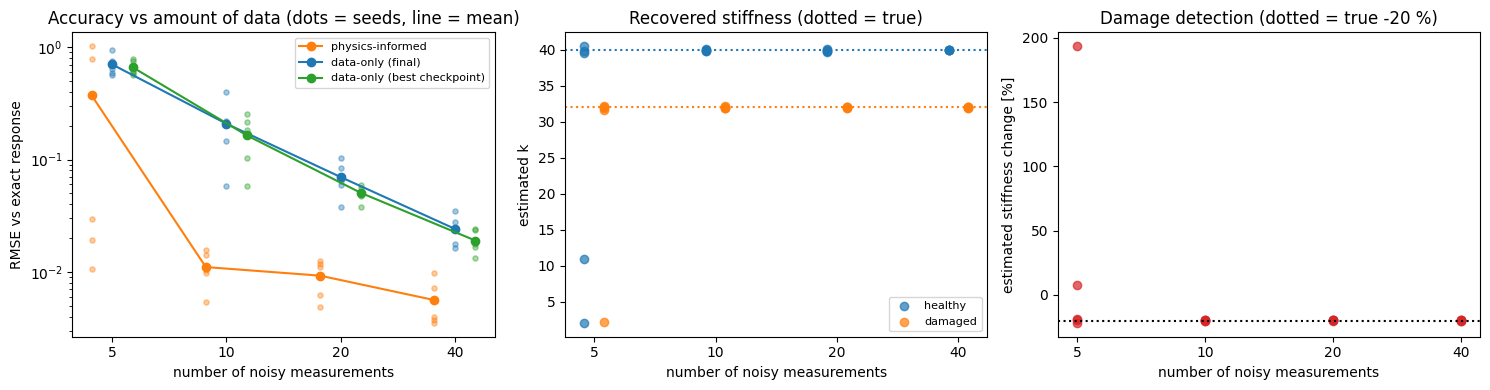

In [12]:
pos = np.arange(len(N_LIST))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

series = [("pinn", "physics-informed", "C1"), ("base_final", "data-only (final)", "C0"), ("base_best", "data-only (best checkpoint)", "C2")]
for j, (key, name, col) in enumerate(series):
    xs = pos + (j - 1) * 0.18
    for i, n in enumerate(N_LIST):
        ax[0].scatter(np.full(len(SEEDS), xs[i]), res[n][key], s=14, color=col, alpha=0.4)
    ax[0].plot(xs, [np.mean(res[n][key]) for n in N_LIST], "o-", color=col, label=name)
ax[0].set_xticks(pos); ax[0].set_xticklabels(N_LIST); ax[0].set_yscale("log")
ax[0].set_xlabel("number of noisy measurements"); ax[0].set_ylabel("RMSE vs exact response")
ax[0].set_title("Accuracy vs amount of data (dots = seeds, line = mean)"); ax[0].legend(fontsize=8)

for i, n in enumerate(N_LIST):
    ax[1].scatter(np.full(len(SEEDS), pos[i]) - 0.08, res[n]["k_h"], color="C0", alpha=0.7, label="healthy" if i == 0 else None)
    ax[1].scatter(np.full(len(SEEDS), pos[i]) + 0.08, res[n]["k_d"], color="C1", alpha=0.7, label="damaged" if i == 0 else None)
ax[1].axhline(K_TRUE, color="C0", ls=":"); ax[1].axhline(K_DAMAGED, color="C1", ls=":")
ax[1].set_xticks(pos); ax[1].set_xticklabels(N_LIST)
ax[1].set_xlabel("number of noisy measurements"); ax[1].set_ylabel("estimated k")
ax[1].set_title("Recovered stiffness (dotted = true)"); ax[1].legend(fontsize=8)

for i, n in enumerate(N_LIST):
    ch = 100 * (np.array(res[n]["k_d"]) - np.array(res[n]["k_h"])) / np.array(res[n]["k_h"])
    ax[2].scatter(np.full(len(SEEDS), pos[i]), ch, color="C3", alpha=0.7)
ax[2].axhline(-20, color="k", ls=":")
ax[2].set_xticks(pos); ax[2].set_xticklabels(N_LIST)
ax[2].set_xlabel("number of noisy measurements"); ax[2].set_ylabel("estimated stiffness change [%]")
ax[2].set_title("Damage detection (dotted = true -20 %)")
plt.tight_layout(); plt.show()

## 9. Limitations 
* The model form is assumed exactly right: mass and damping are known, the initial conditions are known, and the physics is a single-degree-of-freedom linear oscillator. Real structures violate all of this (model-form error is the main difficulty of simulation-to-real transfer).
* Only free vibration is used. Real monitoring data comes from ambient or unknown excitation.
* Only stiffness is unknown. If damping were also unknown, `k` and `c` could trade off against each other (identifiability).
* The "best checkpoint" baseline uses the exact solution to pick its best result, which favours the baseline.
* Results come from a handful of seeds, not a full statistical study.